## Analyzing big NSGAII run

In [1]:
import os
import re
import glob
import json
import numpy as np
import pandas as pd
from pymoo.indicators.hv import HV
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.patches import Rectangle
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap, BoundaryNorm
from matplotlib.lines import Line2D
from scipy.stats import spearmanr

In [2]:
output_folder = "/storage/users/anne_sophie/nsgaii_fI_fSA_h63"
# all slurm job files need to be added here
log_files = ["log_nsgaii_fI_fSA_3022465.out", "log_nsgaii_fI_fSA_3023681.out"]
comparison_generation = None # none means last one
highlight_particle = None

In [3]:
per_seed = pd.read_csv(os.path.join(output_folder, "per_seed.csv"))
runs = per_seed.drop_duplicates(["generation", "strategy", "seed_index"]).copy()
runs["strategy_id"] = runs["generation"].astype(str) + "_" + runs["strategy"].astype(str)   
means = runs.groupby(["generation", "strategy", "strategy_id"]).mean(numeric_only=True).reset_index()
 
run_settings_per_start = {}
for path in glob.glob(os.path.join(output_folder, "run_settings*.json")):
    start = int((re.findall(r"from_generation_(\d+)", path) or ["0"])[0])
    with open(path) as file:
        run_settings_per_start[start] = json.load(file)
run_settings = run_settings_per_start[min(run_settings_per_start)]
objectives = run_settings["objectives"]               
health, cost = objectives
continued_from = sorted(start for start in run_settings_per_start if start > 0)
generations = [int(generation) for generation in sorted(means["generation"].unique())]
print(f"Generations: {generations}")
if comparison_generation is None:
    comparison_generation = continued_from[-1] if continued_from else generations[-1]
job_of_generation = {generation: 1 + sum(generation > start for start in continued_from) for generation in generations}
print("Which generation was in which job?", job_of_generation)

Generations: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17]
Which generation was in which job? {0: 1, 1: 1, 2: 1, 3: 1, 4: 1, 5: 1, 6: 1, 7: 1, 8: 1, 9: 1, 10: 1, 11: 2, 12: 2, 13: 2, 14: 2, 15: 2, 16: 2, 17: 2}


Help functions

In [4]:
def non_dominated_mask(points):
    return np.array([not ((points <= point).all(axis=1) & (points < point).any(axis=1)).any() for point in points])

def front_of(frame): # sorted by cost
    return frame[non_dominated_mask(frame[objectives].to_numpy())].sort_values(cost)

def additive_epsilon(front_a, front_b): # epsilon indicator
    differences = front_a[:, np.newaxis, :] - front_b[np.newaxis, :, :]
    return differences.max(axis=2).min(axis=0).max()

def standard_errors_of_differences(table):
    return table.std(axis=1, ddof=1) / np.sqrt(table.shape[1])

def summarize(standard_errors):
    return {"median": np.median(standard_errors), "mean": standard_errors.mean(),
            "pooled": np.sqrt((standard_errors ** 2).mean())}

Print for every generation time, duration and short overview of performance
 

In [5]:
def parse_log(path, job):
    rows, last_pymoo, last_time, simulations = [], None, 0.0, 0
    text = open(path, errors="replace").read()
    for line in text.splitlines():
        pymoo_match = re.match(r"^\s+(\d+) \|\s+(\d+) \|\s+(\d+) \|\s+(\S+) \|\s+(\S+)", line)
        if pymoo_match:
            last_pymoo = pymoo_match.groups()
        if "Time for advancing simulation" in line:
            simulations += 1
        saved_match = re.search(r"Saved population of generation (\d+), time ([\d.]+) s", line)
        if saved_match:
            time_point = float(saved_match.group(2))
            rows.append({"generation": int(saved_match.group(1)), "job": job, "duration_h": (time_point - last_time) / 3600,
                         "simulations": simulations, "n_nds": last_pymoo[2] if last_pymoo else "-",
                         "pymoo_eps": last_pymoo[3] if last_pymoo else "-"})
            last_time, simulations = time_point, 0
    advance_times = [float(time) for time in re.findall(r"Time for advancing simulation: ([\d.]+)", text)]
    summary = {"job": job, "log": os.path.basename(path), "cpus": (re.findall(r"CPUs: (\d+)", text) or ["?"])[0],
               "simulations": len(advance_times), "failed": text.count("[FAILED]"),
               "advance_mean_s": round(np.mean(advance_times)) if advance_times else None,
               "finished": "Pareto front:" in text}
    return rows, summary
 
 
log_rows, log_summaries = [], []
for job, path in enumerate([path for path in log_files if os.path.exists(path)], start=1):
    rows, summary = parse_log(path, job)
    log_rows += rows
    log_summaries.append(summary)
generation_log = pd.DataFrame(log_rows)
print(generation_log)

    generation  job  duration_h  simulations n_nds     pymoo_eps
0            0    1    6.013056          576     3             -
1            1    1    6.005000          576     4  0.1084473136
2            2    1    6.003056          576     9  0.2160827651
3            3    1    6.005278          576    11  0.1067952147
4            4    1    5.995278          576    12  0.0355531899
5            5    1    5.984722          576    18  0.0319017416
6            6    1    5.991389          576    19  0.0172626861
7            7    1    5.987222          576    24  0.0611777122
8            8    1    5.993333          576    18  0.0025246854
9            9    1    6.007222          576    18  0.0060617079
10          10    1    5.979722          576    24  0.0045861835
11          10    2    0.000000            0    24             -
12          11    2    5.990278          576    26  0.0029325976
13          12    2    5.995278          576    27  0.0040428935
14          13    2    6.

In [23]:
print(generation_log.to_latex())

\begin{tabular}{lrrrrll}
\toprule
 & generation & job & duration_h & simulations & n_nds & pymoo_eps \\
\midrule
0 & 0 & 1 & 6.013056 & 576 & 3 & - \\
1 & 1 & 1 & 6.005000 & 576 & 4 & 0.1084473136 \\
2 & 2 & 1 & 6.003056 & 576 & 9 & 0.2160827651 \\
3 & 3 & 1 & 6.005278 & 576 & 11 & 0.1067952147 \\
4 & 4 & 1 & 5.995278 & 576 & 12 & 0.0355531899 \\
5 & 5 & 1 & 5.984722 & 576 & 18 & 0.0319017416 \\
6 & 6 & 1 & 5.991389 & 576 & 19 & 0.0172626861 \\
7 & 7 & 1 & 5.987222 & 576 & 24 & 0.0611777122 \\
8 & 8 & 1 & 5.993333 & 576 & 18 & 0.0025246854 \\
9 & 9 & 1 & 6.007222 & 576 & 18 & 0.0060617079 \\
10 & 10 & 1 & 5.979722 & 576 & 24 & 0.0045861835 \\
11 & 10 & 2 & 0.000000 & 0 & 24 & - \\
12 & 11 & 2 & 5.990278 & 576 & 26 & 0.0029325976 \\
13 & 12 & 2 & 5.995278 & 576 & 27 & 0.0040428935 \\
14 & 13 & 2 & 6.024444 & 576 & 36 & 0.0070513588 \\
15 & 14 & 2 & 6.001667 & 576 & 39 & 0.0123363172 \\
16 & 15 & 2 & 5.986667 & 576 & 40 & 0.0071127084 \\
17 & 16 & 2 & 5.987222 & 576 & 45 & 0.0051193795 \

Check if 
- there were any problems (mismatch in amounts, etc)
- any failed processes
- all parameter were chosen as thought

In [6]:
changed = sorted({key for settings in run_settings_per_start.values() for key in settings
                  if key not in ("new_generations", "pymoo_seed")
                  and len({json.dumps(other.get(key), sort_keys=True) for other in run_settings_per_start.values()}) > 1})
rows_per_generation = per_seed.groupby("generation").size()
expected_rows = run_settings["population_size"] * len(run_settings["seed_indices"])
wrong_rows = rows_per_generation[(rows_per_generation != expected_rows) & (rows_per_generation.index > 0)]
 
print(f"Lauf: {output_folder}")
print(f"Ziele {objectives}, Constraints {run_settings.get('constraints') or 'keine'}, "
      f"Population {run_settings['population_size']}, \nPartikel {run_settings['seed_indices']}")
print(f"KAPPA_FACTOR {run_settings.get('kappa_factor')}, Simulation/Auswertung bis Tag "
      f"{run_settings.get('simulation_days')}/{run_settings.get('evaluation_end_day')}, Wechseltage "
      f"{run_settings.get('earliest_change_day')}-{run_settings.get('latest_change_day')} (Abstand {run_settings.get('minimum_period_days')})")
print(f"Kontaktdateien {run_settings.get('contact_files')}")
print(f"Generation 0 aus {run_settings.get('generation_0_folder', 'diesem Lauf')}")
print(f"Starts bei Generation {sorted(run_settings_per_start)}, geänderte Einstellungen: {changed or 'keine'}")
print(f"Generationen 0-{generations[-1]}, Strategien {len(means)}, \nZeilen in per_seed {len(per_seed)}, "
      f"falsche Zeilenzahl: {wrong_rows.to_dict() or 'keine'}, fehlende Zielwerte {per_seed[objectives].isna().any(axis=1).sum()}")
if log_summaries:
    print("\n" + pd.DataFrame(log_summaries).to_string(index=False))
    simulated = generation_log[generation_log["simulations"] > 0]
    print(f"\nDauer pro Generation im Mittel {simulated['duration_h'].mean():.1f} h, gesamt {generation_log['duration_h'].sum():.1f} h")
 

Lauf: /storage/users/anne_sophie/nsgaii_fI_fSA_h63
Ziele ['f_I', 'f_S_A'], Constraints keine, Population 48, 
Partikel [19, 23, 28, 35, 41, 44, 50, 51, 52, 53, 58, 71]
KAPPA_FACTOR 2.2, Simulation/Auswertung bis Tag 63/63, Wechseltage 19-49 (Abstand 7)
Kontaktdateien {'Home': ['baseline_home.txt', 1.0], 'School': ['baseline_school_pf_eig.txt', 1.0], 'Work': ['baseline_work.txt', 1.0], 'SocialEvent': ['baseline_other.txt', 0.6], 'BasicsShop': ['baseline_other.txt', 0.4]}
Generation 0 aus /storage/users/anne_sophie/screening_kappa_2.2_12_seeds_h77_d19_notest
Starts bei Generation [0, 10], geänderte Einstellungen: keine
Generationen 0-17, Strategien 864, 
Zeilen in per_seed 10944, falsche Zeilenzahl: keine, fehlende Zielwerte 0

 job                           log cpus  simulations  failed  advance_mean_s  finished
   1 log_nsgaii_fI_fSA_3022465.out   48         6336       0            1730      True
   2 log_nsgaii_fI_fSA_3023681.out   48         4032       0            1729      True

Da

Check convergence: 
1) Take mean of all 12 ("Partikel") particles for every strategy
2) Standardise (because the two objectives are too far from each other)
    $$f_{standardised} = (f - ideal_{point}) / (nadir_{point} - ideal_{point})$$
    ideal_point: best value of every objective
    nadir_point: worst value of every objective on the final front
    // for every generation the same (!)
3) Take all non-dominated strategies of every generation (we will call it archive)
4) Calculate Hypervolume 
5) Calculate epsilon indicator
6) Check noise: how small can a improvement be s.t. we can still prove it with 12 particles? (for all pairs of strategies calculate difference between particles and then take standard error)

In [7]:
# 2
raw_points = means[objectives].to_numpy()
on_final_front = non_dominated_mask(raw_points)
ideal, nadir = raw_points[on_final_front].min(axis=0), raw_points[on_final_front].max(axis=0)
normalized = (raw_points - ideal) / (nadir - ideal)
reference_value = 1 + 1 / (run_settings["population_size"] - 1)
hypervolume = HV(ref_point=np.full(2, reference_value))
print(f"Idealpunkt {ideal.round(4).tolist()}, Nadirpunkt {nadir.round(4).tolist()}, Referenzpunkt {reference_value:.4f}")
# 3 
archives = {}
for generation in generations:
    points = normalized[means["generation"].to_numpy() <= generation]
    archives[generation] = points[non_dominated_mask(points)]
# 4 and 5
rows = []
for generation in generations:
    rows.append({"generation": generation, "job": job_of_generation[generation],
                 "front_points": len(archives[generation]),
                 "hypervolume": hypervolume(archives[generation]),
                 "eps_to_previous": additive_epsilon(archives[generation - 1], archives[generation]) if generation > 0 else np.nan,
                 "eps_to_final": additive_epsilon(archives[generation], archives[generations[-1]])})
progress = pd.DataFrame(rows)
progress["hv_change_percent"] = 100 * progress["hypervolume"].pct_change()
print(progress.round(4).to_string(index=False))

Idealpunkt [18500.9167, 0.057], Nadirpunkt [27512.25, 0.5039], Referenzpunkt 1.0213


 generation  job  front_points  hypervolume  eps_to_previous  eps_to_final  hv_change_percent
          0    1             3       0.3412              NaN        0.4670                NaN
          1    1             4       0.4777           0.1977        0.3453            39.9979
          2    1             9       0.5554           0.2210        0.2749            16.2678
          3    1            11       0.6289           0.1658        0.1911            13.2431
          4    1            12       0.6491           0.0424        0.1911             3.2027
          5    1            18       0.6823           0.0754        0.1850             5.1194
          6    1            19       0.7292           0.1185        0.1185             6.8755
          7    1            24       0.7525           0.0615        0.1185             3.1896
          8    1            18       0.7761           0.0673        0.0962             3.1486
          9    1            18       0.7992           0.0509

Attention: the first job was done with pymoo seed (! not our particle seed) = 1 for job 1 and then took from the random stream. We didn't save that and the second job was then started with a random stream starting at 11

In [8]:
# 6
span = nadir - ideal
health_table = runs.pivot(index="strategy_id", columns="seed_index", values=health)
front_ids = means.loc[on_final_front].sort_values(cost)["strategy_id"].tolist()    
all_ids = health_table.index.to_numpy()
first, second = np.triu_indices(len(all_ids), k=1)
all_pairs = health_table.to_numpy()[first] - health_table.to_numpy()[second]
front_values = health_table.loc[front_ids].to_numpy()
front_first, front_second = np.triu_indices(len(front_ids), k=1)
noise = {"alle Paare": summarize(standard_errors_of_differences(all_pairs)),
         "Endfront, alle Paare": summarize(standard_errors_of_differences(front_values[front_first] - front_values[front_second])),
         "Endfront, Nachbarn": summarize(standard_errors_of_differences(np.diff(front_values, axis=0)))}
print(f"Rauschen von {health} als Anteil der Spannweite ({span[0]:.0f}):")
for label, values in noise.items():
    print(f"   {label:>21}: " + ", ".join(f"{name} {value / span[0]:.4f}" for name, value in values.items())
          + f"  (pooled absolut {values['pooled']:.0f})")
noise_threshold = noise["Endfront, Nachbarn"]["pooled"] / span[0]    
print(f"Schwelle: Nachbarn auf der Endfront, pooled = {noise_threshold:.4f}")

Rauschen von f_I als Anteil der Spannweite (9011):
              alle Paare: median 0.0518, mean 0.0622, pooled 0.0755  (pooled absolut 680)
    Endfront, alle Paare: median 0.0418, mean 0.0507, pooled 0.0625  (pooled absolut 563)
      Endfront, Nachbarn: median 0.0046, mean 0.0064, pooled 0.0091  (pooled absolut 82)
Schwelle: Nachbarn auf der Endfront, pooled = 0.0091


For the first run ever: was it good to do a second job? Did it help?

In [9]:
before, after = archives[comparison_generation], archives[generations[-1]]
improvement = additive_epsilon(before, after)
print(f"Generation {comparison_generation} -> {generations[-1]}: Hypervolumen {hypervolume(before):.4f} -> {hypervolume(after):.4f} "
      f"(+{100 * (hypervolume(after) / hypervolume(before) - 1):.2f} %)")
print(f"epsilon {improvement:.4f} (= {improvement * span[0]:.0f} {health}), Rauschschwelle {noise_threshold:.4f}; "
      f"umgekehrt {additive_epsilon(after, before):.4f} (muss 0 sein)")
final_members = means.loc[on_final_front, ["generation", "strategy"] + objectives].copy()
final_members["gain"] = [max(0.0, (before - point).max(axis=1).min()) for point in normalized[on_final_front]]
final_members = final_members.sort_values(cost)
print(f"Endfront: {len(final_members)} Strategien, gefunden in Generation "
      f"{final_members['generation'].value_counts().sort_index().to_dict()}")
print(final_members.round(4).to_string(index=False))

Generation 10 -> 17: Hypervolumen 0.8157 -> 0.8720 (+6.90 %)
epsilon 0.0800 (= 721 f_I), Rauschschwelle 0.0091; umgekehrt 0.0000 (muss 0 sein)
Endfront: 56 Strategien, gefunden in Generation {9: 1, 11: 2, 12: 3, 13: 6, 14: 5, 15: 10, 16: 13, 17: 16}
 generation  strategy        f_I  f_S_A   gain
         14        13 27512.2500 0.0570 0.0312
         16         6 27483.2500 0.0572 0.0308
         17        39 27458.1667 0.0572 0.0308
         16        26 26913.5833 0.0602 0.0359
         17        29 26858.6667 0.0655 0.0328
         13        18 26825.2500 0.0669 0.0365
         11        14 26805.3333 0.0698 0.0387
         17        26 26413.5833 0.0717 0.0542
         17        15 26345.0000 0.0728 0.0518
         16        37 26326.7500 0.0728 0.0518
         17         0 26121.3333 0.0773 0.0417
         13        10 25648.1667 0.0774 0.0415
         17        37 25592.0000 0.0779 0.0403
         16        40 25530.1667 0.0815 0.0324
         17        25 24428.8333 0.0827 0.053

Gain: Abstand zur Front nach Generation 10

Plot: Convergence over generations

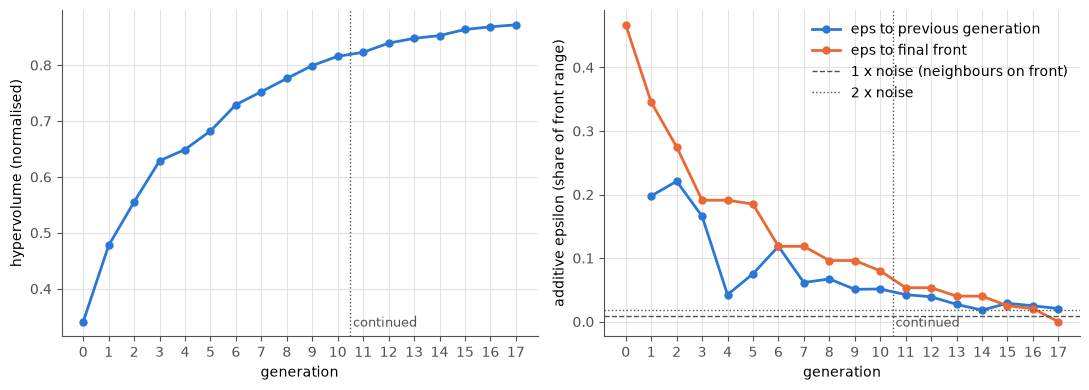

In [10]:
plt.rcParams.update({"font.size": 10, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.edgecolor": "#52514e", "xtick.color": "#52514e", "ytick.color": "#52514e"})
blue, orange, ink, grey, grid_color = "#2a78d6", "#eb6834", "#0b0b0b", "#9a9890", "#e4e3df"
 
figure, (left, right) = plt.subplots(1, 2, figsize=(11, 4))
left.plot(progress["generation"], progress["hypervolume"], color=blue, linewidth=2, marker="o", markersize=5)
left.set_ylabel("hypervolume (normalised)")
right.plot(progress["generation"], progress["eps_to_previous"], color=blue, linewidth=2, marker="o", markersize=5,
           label="eps to previous generation")
right.plot(progress["generation"], progress["eps_to_final"], color=orange, linewidth=2, marker="o", markersize=5,
           label="eps to final front")
right.axhline(noise_threshold, color="#52514e", linewidth=1, linestyle="--", label="1 x noise (neighbours on front)")
right.axhline(2 * noise_threshold, color="#52514e", linewidth=1, linestyle=":", label="2 x noise")
right.set_ylabel("additive epsilon (share of front range)")
right.legend(frameon=False)
for axis in (left, right):
    axis.grid(color=grid_color, linewidth=0.8)
    axis.set_axisbelow(True)
    axis.set_xlabel("generation")
    axis.set_xticks(generations)
    for start in continued_from:
        axis.axvline(start + 0.5, color="#52514e", linewidth=1, linestyle=":")
        axis.text(start + 0.6, 0.03, "continued", transform=axis.get_xaxis_transform(), color="#52514e", fontsize=9)
figure.tight_layout()
plt.show()

Heatmap: every generation against each other (epsilon indicator)

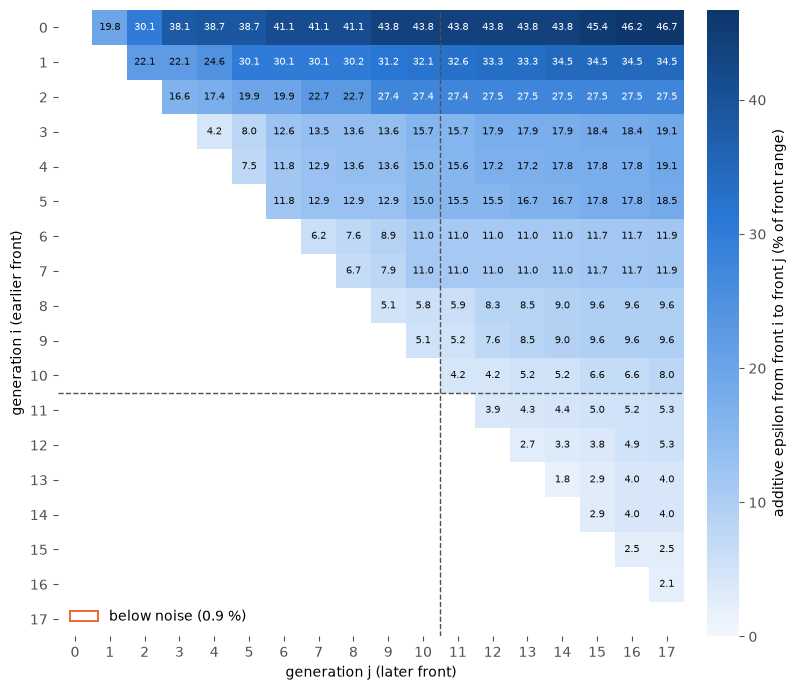

In [11]:
size = len(generations)
epsilon_matrix = np.full((size, size), np.nan)
for row, generation_i in enumerate(generations):
    for column, generation_j in enumerate(generations):
        if generation_j > generation_i:
            epsilon_matrix[row, column] = additive_epsilon(archives[generation_i], archives[generation_j])
 
heatmap_ramp = LinearSegmentedColormap.from_list("epsilon", ["#f4f8fd", "#86b6ef", "#2a78d6", "#0d366b"])
figure, axis = plt.subplots(figsize=(8.5, 7))
image = axis.imshow(100 * epsilon_matrix, cmap=heatmap_ramp, vmin=0)
show_numbers = size <= 20                       # für Folien auf False setzen
for row in range(size):
    for column in range(row + 1, size):
        value = epsilon_matrix[row, column]
        if show_numbers:
            axis.text(column, row, f"{100 * value:.1f}", ha="center", va="center", fontsize=7,
                      color="white" if value > 0.55 * np.nanmax(epsilon_matrix) else ink)
        if value < noise_threshold:
            axis.add_patch(Rectangle((column - 0.5, row - 0.5), 1, 1, fill=False, edgecolor=orange, linewidth=1.4))
for start in continued_from:
    axis.axhline(generations.index(start) + 0.5, color="#52514e", linewidth=1, linestyle="--")
    axis.axvline(generations.index(start) + 0.5, color="#52514e", linewidth=1, linestyle="--")
axis.set_xticks(range(size), generations)
axis.set_yticks(range(size), generations)
axis.set_xlabel("generation j (later front)")
axis.set_ylabel("generation i (earlier front)")
for spine in axis.spines.values():
    spine.set_visible(False)
colorbar = figure.colorbar(image, ax=axis, fraction=0.046, pad=0.03)
colorbar.set_label("additive epsilon from front i to front j (% of front range)")
colorbar.outline.set_visible(False)
axis.legend(handles=[Rectangle((0, 0), 1, 1, fill=False, edgecolor=orange, linewidth=1.4,
                               label=f"below noise ({100 * noise_threshold:.1f} %)")], frameon=False, loc="lower left")
figure.tight_layout()
plt.show()

Plots of the front

In [12]:
settled = [generation for row, generation in enumerate(generations[:-1]) if np.nanmax(epsilon_matrix[row, row + 1:]) < noise_threshold]
print(f"Generationen, nach denen keine spätere mehr als das Rauschen bringt: {settled or 'keine'}")

Generationen, nach denen keine spätere mehr als das Rauschen bringt: keine


Alle Mean of Strategys, all non-dominated and final front

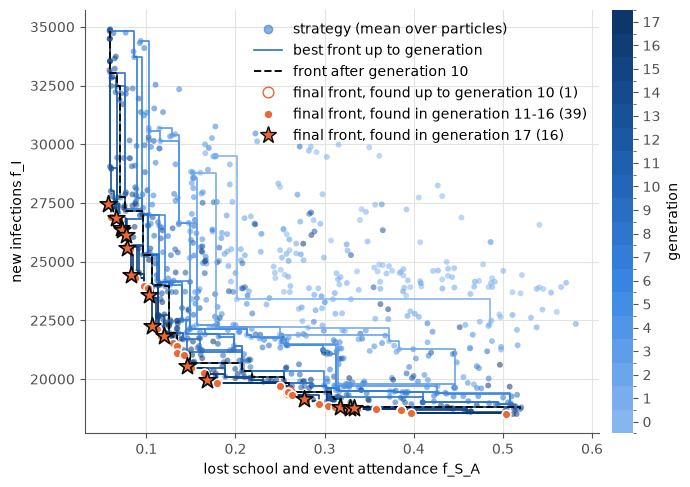

In [13]:
axis_labels = {"f_I": "new infections f_I", "f_S_A": "lost school and event attendance f_S_A",
               "f_W": "lost working attendance f_W", "f_ED": "expected deaths f_ED"}
generation_ramp = LinearSegmentedColormap.from_list("generations", ["#86b6ef", "#3987e5", "#1c5cab", "#0d366b"])
color_norm = BoundaryNorm(np.arange(generations[0] - 0.5, generations[-1] + 1.5), generation_ramp.N)
final_front = front_of(means)

figure, axis = plt.subplots(figsize=(8, 5.5))
axis.scatter(means[cost], means[health], c=means["generation"], cmap=generation_ramp, norm=color_norm,
             s=18, alpha=0.55, linewidths=0)
for generation in generations:
    front = front_of(means[means["generation"] <= generation])
    axis.step(front[cost], front[health], where="post", color=generation_ramp(color_norm(generation)), linewidth=1.2)
comparison_front = front_of(means[means["generation"] <= comparison_generation])
axis.step(comparison_front[cost], comparison_front[health], where="post", color=ink, linewidth=1.4, linestyle="--")

# Endfront nach Herkunft: hohl = schon bis comparison_generation gefunden, voll = danach, Stern = letzte Generation
last_generation = generations[-1]
found_in = final_front["generation"]
origin_groups = [(found_in <= comparison_generation, "o", "white", orange, 60, f"up to generation {comparison_generation}"),
                 ((found_in > comparison_generation) & (found_in < last_generation), "o", orange, "white", 40,
                  f"in generation {comparison_generation + 1}-{last_generation - 1}"),
                 (found_in == last_generation, "*", orange, ink, 160, f"in generation {last_generation}")]
for found, marker, face, edge, size, _ in origin_groups:
    axis.scatter(final_front.loc[found, cost], final_front.loc[found, health], marker=marker, s=size,
                 facecolors=face, edgecolors=edge, linewidths=1.2, zorder=5)

colorbar = figure.colorbar(plt.cm.ScalarMappable(norm=color_norm, cmap=generation_ramp), ax=axis, ticks=generations, pad=0.02)
colorbar.set_label("generation")
colorbar.outline.set_visible(False)
axis.legend(handles=[Line2D([], [], marker="o", linestyle="", color=generation_ramp(0.5), alpha=0.55, label="strategy (mean over particles)"),
                     Line2D([], [], color=generation_ramp(0.5), linewidth=1.2, label="best front up to generation"),
                     Line2D([], [], color=ink, linewidth=1.4, linestyle="--", label=f"front after generation {comparison_generation}")]
                    + [Line2D([], [], marker=marker, linestyle="", markerfacecolor=face, markeredgecolor=edge, markersize=np.sqrt(size),
                              label=f"final front, found {label} ({found.sum()})")
                       for found, marker, face, edge, size, label in origin_groups],
            frameon=False, loc="upper right")
axis.grid(color=grid_color, linewidth=0.8)
axis.set_axisbelow(True)
axis.set_xlabel(axis_labels.get(cost, cost))
axis.set_ylabel(axis_labels.get(health, health))
plt.show()

Different strategies with each particle

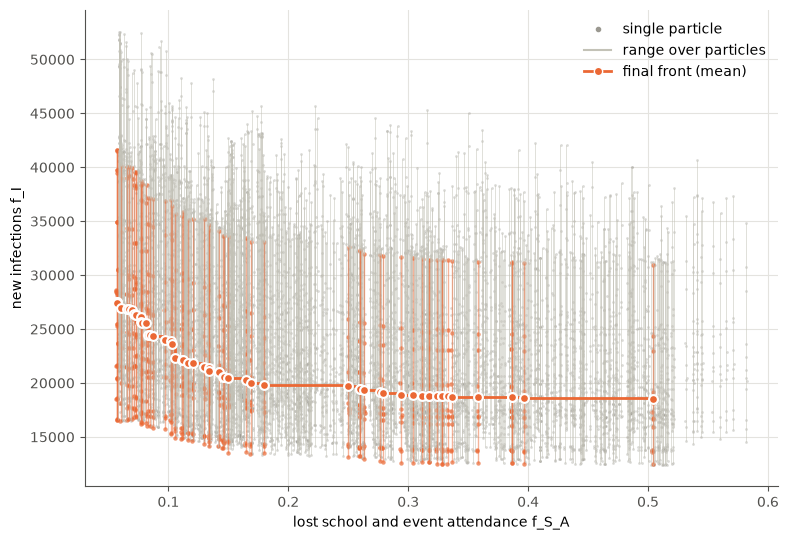

In [14]:
runs_with_mean = runs.merge(means[["strategy_id", cost]].rename(columns={cost: "mean_cost"}), on="strategy_id")
spans = runs_with_mean.groupby("strategy_id").agg(x=("mean_cost", "first"), low=(health, "min"), high=(health, "max"))
is_front = spans.index.isin(front_ids)
run_is_front = runs_with_mean["strategy_id"].isin(front_ids)
 
figure, axis = plt.subplots(figsize=(8, 5.5))
axis.vlines(spans.loc[~is_front, "x"], spans.loc[~is_front, "low"], spans.loc[~is_front, "high"], color="#c3c2b7", linewidth=0.6, alpha=0.6)
axis.scatter(runs_with_mean.loc[~run_is_front, cost], runs_with_mean.loc[~run_is_front, health], s=4, color=grey, alpha=0.35, linewidths=0)
axis.vlines(spans.loc[is_front, "x"], spans.loc[is_front, "low"], spans.loc[is_front, "high"], color=orange, linewidth=1, alpha=0.5)
axis.scatter(runs_with_mean.loc[run_is_front, cost], runs_with_mean.loc[run_is_front, health], s=10, color=orange, alpha=0.7, linewidths=0)
axis.step(final_front[cost], final_front[health], where="post", color=orange, linewidth=2)
axis.scatter(final_front[cost], final_front[health], s=40, color=orange, edgecolors="white", linewidths=1.5, zorder=5)
handles = [Line2D([], [], marker="o", linestyle="", color=grey, markersize=3, label="single particle"),
           Line2D([], [], color="#c3c2b7", label="range over particles"),
           Line2D([], [], color=orange, marker="o", markeredgecolor="white", linewidth=2, label="final front (mean)")]
if highlight_particle is not None:
    chosen = runs_with_mean[runs_with_mean["seed_index"] == highlight_particle]
    axis.scatter(chosen[cost], chosen[health], s=12, color=blue, linewidths=0, zorder=4)
    handles.append(Line2D([], [], marker="o", linestyle="", color=blue, markersize=4, label=f"particle {highlight_particle}"))
axis.legend(handles=handles, frameon=False, loc="upper right")
axis.grid(color=grid_color, linewidth=0.8)
axis.set_axisbelow(True)
axis.set_xlabel(axis_labels.get(cost, cost))
axis.set_ylabel(axis_labels.get(health, health))
figure.tight_layout()
plt.show()

In [15]:
relative_span = (spans["high"] - spans["low"]) / means.set_index("strategy_id").loc[spans.index, health]
print(f"Spanne von {health} über die Partikel relativ zum Mittel: Median {relative_span.median():.0%}, "
      f"auf der Endfront {relative_span[is_front].median():.0%}")

Spanne von f_I über die Partikel relativ zum Mittel: Median 92%, auf der Endfront 95%


In [16]:
spans_social = runs_with_mean.groupby("strategy_id").agg(x=("mean_cost", "first"), low=(cost, "min"), high=(cost, "max"))
relative_span_social = (spans_social["high"] - spans_social["low"]) / means.set_index("strategy_id").loc[spans_social.index, cost]
print(f"Spanne von {cost} über die Partikel relativ zum Mittel: Median {relative_span_social.median():.3%}, "
      f"auf der Endfront {relative_span_social[is_front].median():.3%}")

Spanne von f_S_A über die Partikel relativ zum Mittel: Median 0.451%, auf der Endfront 0.907%


f_S_A hängt fast nicht vom Partikel ab (siehe)

Same but with /mean

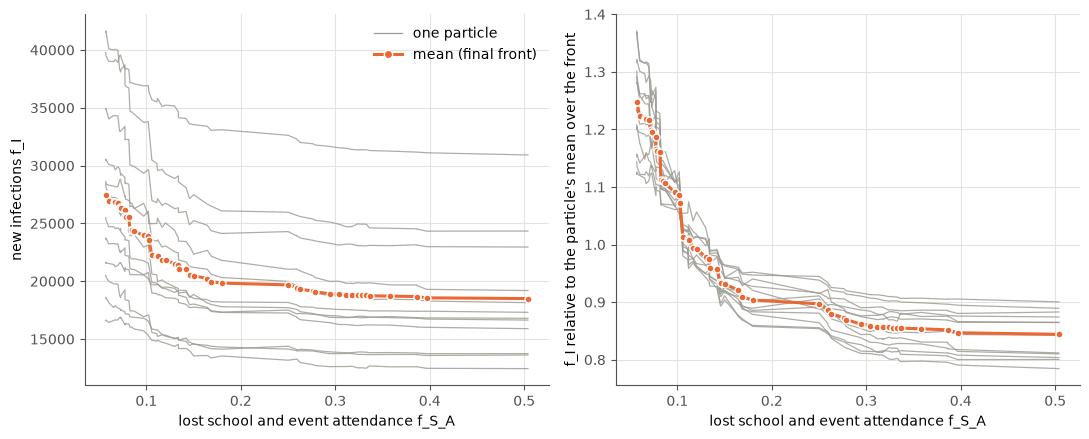

In [17]:
front_table = health_table.loc[front_ids]
front_table.index = means.set_index("strategy_id").loc[front_ids, cost]       # x = Kosten der Strategie
relative = front_table / front_table.mean(axis=0)
mean_line = front_table.mean(axis=1)
 
figure, (left, right) = plt.subplots(1, 2, figsize=(11, 4.5), sharex=True)
for particle in front_table.columns:
    color, width = (blue, 1.6) if particle == highlight_particle else (grey, 0.9)
    left.plot(front_table.index, front_table[particle], color=color, linewidth=width, alpha=0.8)
    right.plot(relative.index, relative[particle], color=color, linewidth=width, alpha=0.8)
for axis, values in [(left, mean_line), (right, relative.mean(axis=1))]:
    axis.plot(values.index, values, color=orange, linewidth=2.2, marker="o", markersize=5, markeredgecolor="white", zorder=5)
    axis.grid(color=grid_color, linewidth=0.8)
    axis.set_axisbelow(True)
    axis.set_xlabel(axis_labels.get(cost, cost))
left.set_ylabel(axis_labels.get(health, health))
right.set_ylabel(f"{health} relative to the particle's mean over the front")
left.legend(handles=[Line2D([], [], color=grey, linewidth=0.9, label="one particle"),
                     Line2D([], [], color=orange, linewidth=2.2, marker="o", markeredgecolor="white", label="mean (final front)")],
            frameon=False, loc="upper right")
figure.tight_layout()
plt.show()

In [18]:
correlations = [spearmanr(front_table[a], front_table[b])[0]
                for index, a in enumerate(front_table.columns) for b in front_table.columns[index + 1:]]
same_direction = np.sign(np.diff(front_table.to_numpy(), axis=0)) == np.sign(np.diff(mean_line.to_numpy()))[:, np.newaxis]
print(f"Spearman zwischen je zwei Partikeln: Median {np.median(correlations):.2f}, Minimum {np.min(correlations):.2f}")
print(f"Nachbarn auf der Front: im Mittel {same_direction.mean():.0%} der Partikel in derselben Richtung wie das Mittel, "
      f"bei {same_direction.all(axis=1).sum()} von {len(same_direction)} Nachbarpaaren alle")
print(f"Spanne pro Strategie relativ zum Mittel: absolut {((front_table.max(axis=1) - front_table.min(axis=1)) / mean_line).median():.0%}, "
      f"nach Teilen durch das Partikelmittel {(relative.max(axis=1) - relative.min(axis=1)).median():.0%}")

Spearman zwischen je zwei Partikeln: Median 0.99, Minimum 0.97
Nachbarn auf der Front: im Mittel 74% der Partikel in derselben Richtung wie das Mittel, bei 12 von 55 Nachbarpaaren alle
Spanne pro Strategie relativ zum Mittel: absolut 95%, nach Teilen durch das Partikelmittel 10%


Descision vectors

In [19]:
generation_0_folder = "/storage/users/anne_sophie/screening_kappa_2.2_12_seeds_h77_d19_notest"
first_run = runs.groupby("strategy_id")[["generation", "number_to_save"]].min()


def decision_vectors(frame):
    # alle 12 Läufe einer Strategie haben dieselbe Strategie, also reicht die json des ersten Laufs
    rows = []
    for _, row in frame.sort_values(cost).iterrows():
        generation, number_to_save = first_run.loc[row["strategy_id"]]
        folder = generation_0_folder if generation == 0 else output_folder
        with open(os.path.join(folder, f"{number_to_save}_strategy.json")) as file:
            stored = json.load(file)
        stored.pop("seed_index")
        rows.append({"strategy_id": row["strategy_id"], health: row[health], cost: row[cost], **stored})
    return pd.DataFrame(rows)


final_front_strategies = decision_vectors(means.loc[on_final_front])
print(final_front_strategies.round(3).to_string(index=False))
final_front_strategies.to_csv(os.path.join(output_folder, "final_front_strategies.csv"), index=False)

# after generation 10
# print(decision_vectors(front_of(means[means["generation"] <= 10])).round(3).to_string(index=False))

strategy_id       f_I  f_S_A  home_office_1  school_closure_1  social_events_1  home_office_2  school_closure_2  social_events_2  change_day_1  change_day_2
      14_13 27512.250  0.057          0.690             0.115            0.055          0.680             0.010            0.006            19            26
       16_6 27483.250  0.057          0.690             0.124            0.055          0.684             0.016            0.001            19            26
      17_39 27458.167  0.057          0.659             0.070            0.055          0.680             0.010            0.006            19            29
      16_26 26913.583  0.060          0.690             0.050            0.135          0.688             0.017            0.006            19            26
      17_29 26858.667  0.065          0.690             0.114            0.055          0.680             0.017            0.006            20            27
      13_18 26825.250  0.067          0.664             0.

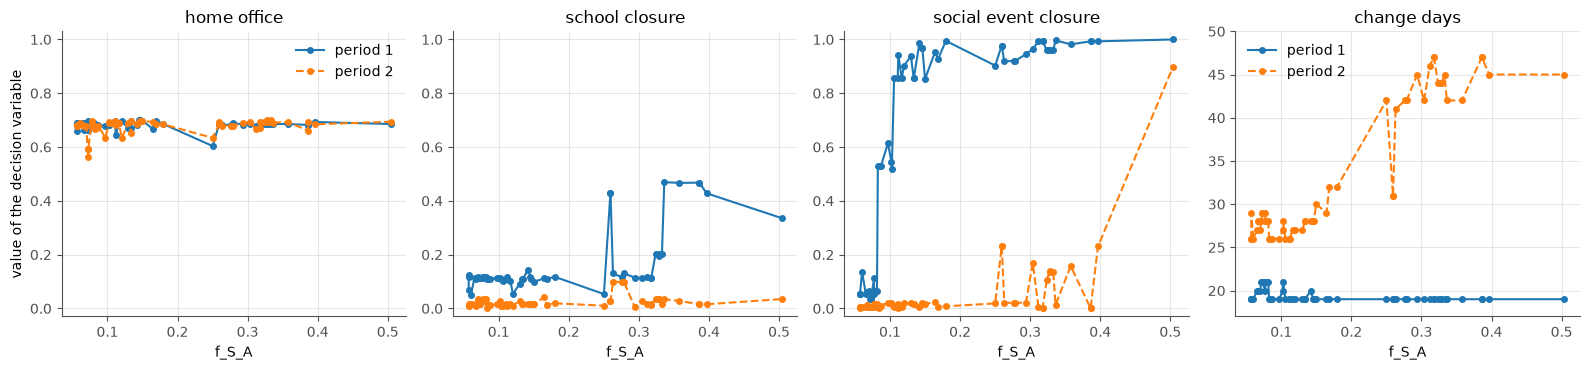

In [20]:
panels = [("home_office", "home office"), ("school_closure", "school closure"),
          ("social_events", "social event closure"), ("change_day", "change days")]
figure, axes = plt.subplots(1, 4, figsize=(16, 3.8), sharex=True)
for axis, (variable, title) in zip(axes, panels):
    for period, line_style in [(1, "-"), (2, "--")]:
        axis.plot(final_front_strategies[cost], final_front_strategies[f"{variable}_{period}"], line_style,
                  marker="o", markersize=4, label=f"period {period}")
    axis.set(title=title, xlabel=cost, ylim=(17, 50) if variable == "change_day" else (-0.03, 1.03))
    axis.grid(alpha=0.3)
axes[0].set_ylabel("value of the decision variable")
axes[3].legend(frameon=False)
axes[0].legend(frameon=False)
figure.tight_layout()

In [21]:
simulation_days = 63
baseline = {"home_office": (19, 0.37), "school_closure": (14, 1.0), "social_events": (19, 0.51)}

def measure_per_day(strategy, measure):
    values = np.zeros(simulation_days)
    start_day, level = baseline[measure]
    values[start_day:strategy["change_day_1"]] = level        
    values[strategy["change_day_1"]:strategy["change_day_2"]] = strategy[f"{measure}_1"]
    values[strategy["change_day_2"]:] = strategy[f"{measure}_2"]
    return values
 

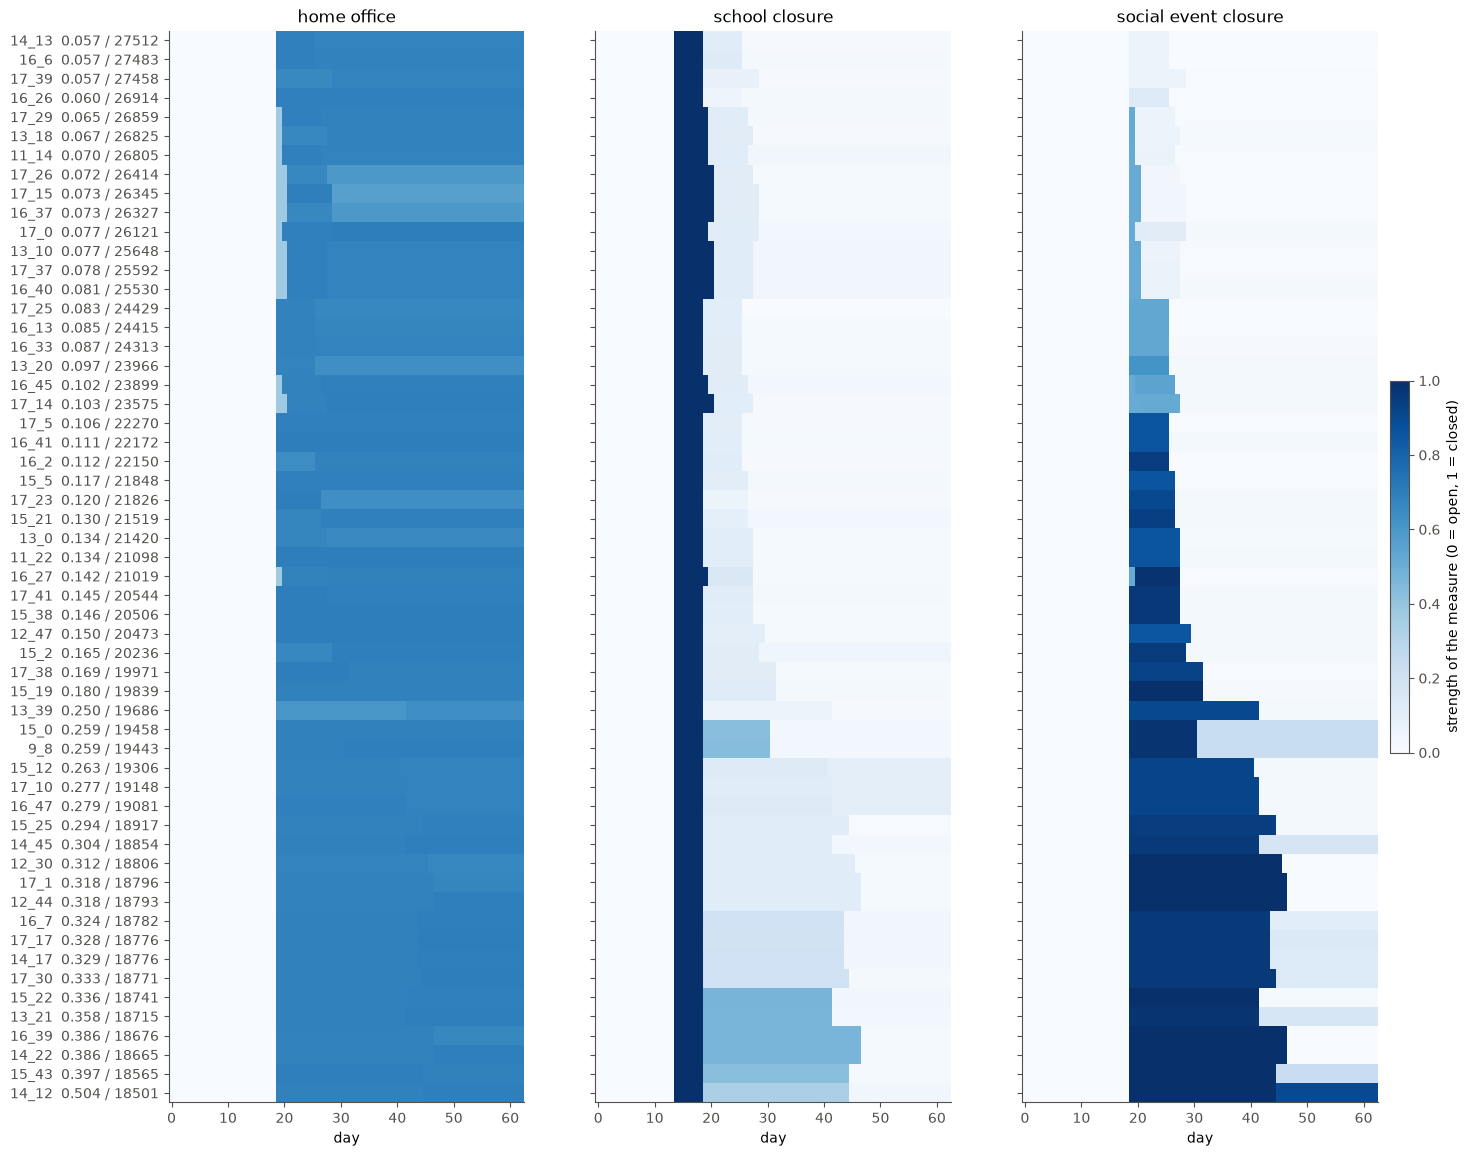

In [22]:
figure, axes = plt.subplots(1, 3, figsize=(16, 0.22 * len(final_front_strategies) + 1.6), sharey=True)
for axis, (measure, title) in zip(axes, panels):
    table = [measure_per_day(strategy, measure) for _, strategy in final_front_strategies.iterrows()]
    image = axis.imshow(table, aspect="auto", cmap="Blues", vmin=0, vmax=1, interpolation="nearest")
    axis.set(title=title, xlabel="day")
axes[0].set_yticks(range(len(final_front_strategies)),
                   [f"{name}  {value:.3f} / {infections:.0f}" for name, value, infections
                    in zip(final_front_strategies["strategy_id"], final_front_strategies[cost], final_front_strategies[health])])
figure.colorbar(image, ax=axes, fraction=0.015, pad=0.01, label="strength of the measure (0 = open, 1 = closed)")